# Explainable Predictive Maintenance System

## 1. Chargement et compréhension des données

In [1]:
!pip install -q ucimlrepo


### 1.1 Téléchargement automatique du dataset AI4I 2020

In [2]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=601)

X = dataset.data.features
y = dataset.data.targets

In [3]:
print("X :", X.shape)
print("y :", y.shape)

X : (10000, 6)
y : (10000, 6)


In [4]:
display(X.head())
display(y.head())

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


,Machine failure,TWF,HDF,PWF,OSF,RNF
0,0,0,0,0,0,0
1,0,0,0,0,0,0
2,0,0,0,0,0,0
3,0,0,0,0,0,0
4,0,0,0,0,0,0


### 1.2 Définition de la cible et distribution des classes

In [5]:
target = y["Machine failure"]

print(target.shape)
print(target.value_counts())

(10000,)
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [6]:
print(target.value_counts(normalize=True) * 100)

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


## 2. Analyse exploratoire des données (EDA)

### 2.1 Vérification de la qualité des données

In [7]:
print(X.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Type                 10000 non-null  object 
 1   Air temperature      10000 non-null  float64
 2   Process temperature  10000 non-null  float64
 3   Rotational speed     10000 non-null  int64  
 4   Torque               10000 non-null  float64
 5   Tool wear            10000 non-null  int64  
dtypes: float64(3), int64(2), object(1)
memory usage: 468.9+ KB
None


In [8]:
print("Valeurs manquantes :")
print(X.isnull().sum())

Valeurs manquantes :
Type                   0
Air temperature        0
Process temperature    0
Rotational speed       0
Torque                 0
Tool wear              0
dtype: int64


In [9]:
print("Doublons :", X.duplicated().sum())

Doublons : 0


### 2.2 Statistiques descriptives

In [10]:
display(X.describe())

,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000
std,2.000259,1.483734,179.284096,9.968934,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


In [11]:
print(X["Type"].value_counts())

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


### 2.3 Analyse des variables par rapport à la panne

In [12]:
df = X.copy()
df["Machine failure"] = target

display(df.head())

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


In [13]:
failure_by_type = df.groupby("Type")["Machine failure"].agg(
    ["count", "sum", "mean"]
)

failure_by_type["failure_rate_%"] = failure_by_type["mean"] * 100

display(failure_by_type)

,count,sum,mean,failure_rate_%
Type,,,,
H,1003,21,0.020937,2.093719
L,6000,235,0.039167,3.916667
M,2997,83,0.027694,2.769436


In [14]:
numeric_features = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

comparison = df.groupby("Machine failure")[numeric_features].mean()

display(comparison)

,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
Machine failure,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


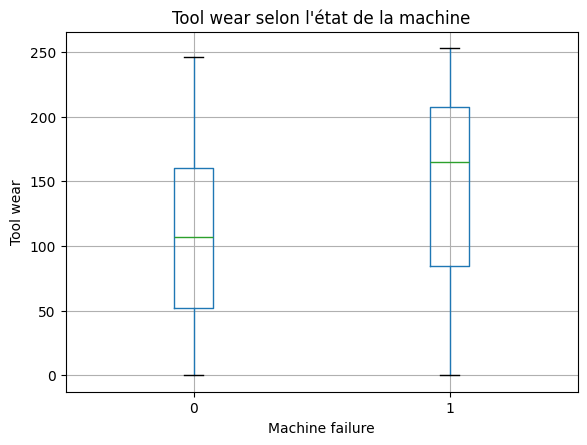

In [15]:
import matplotlib.pyplot as plt

df.boxplot(
    column="Tool wear",
    by="Machine failure"
)

plt.title("Tool wear selon l'état de la machine")
plt.suptitle("")
plt.xlabel("Machine failure")
plt.ylabel("Tool wear")
plt.show()

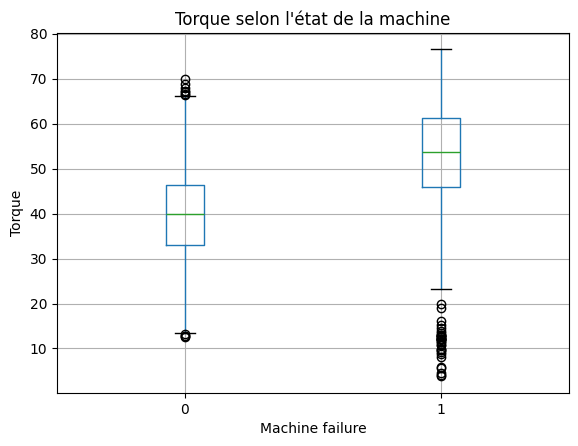

In [16]:
df.boxplot(
    column="Torque",
    by="Machine failure"
)

plt.title("Torque selon l'état de la machine")
plt.suptitle("")
plt.xlabel("Machine failure")
plt.ylabel("Torque")
plt.show()

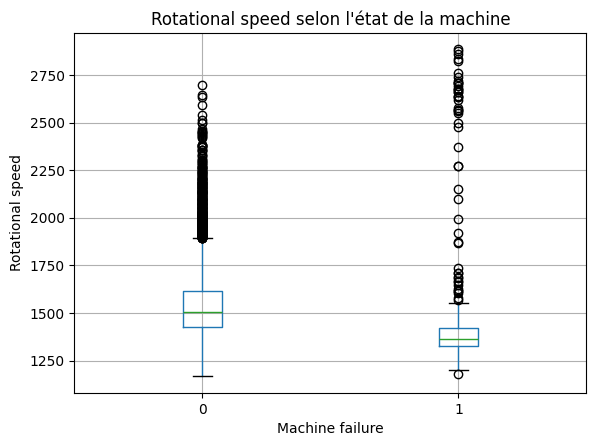

In [17]:
df.boxplot(
    column="Rotational speed",
    by="Machine failure"
)

plt.title("Rotational speed selon l'état de la machine")
plt.suptitle("")
plt.xlabel("Machine failure")
plt.ylabel("Rotational speed")
plt.show()

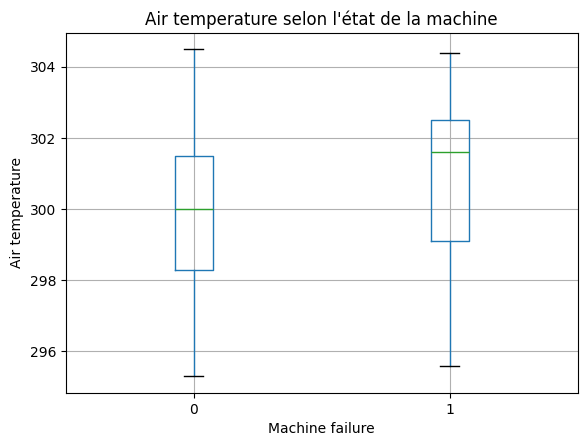

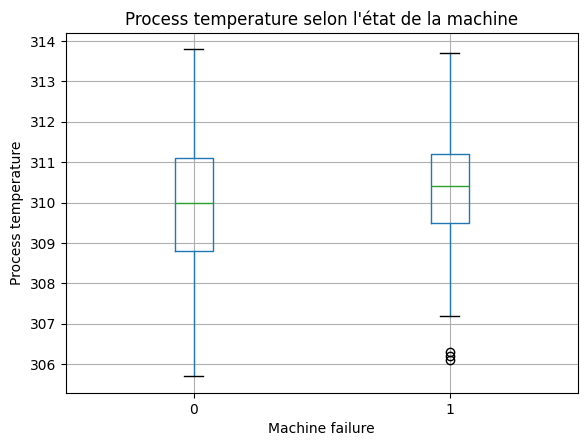

In [18]:
for col in ["Air temperature", "Process temperature"]:
    df.boxplot(column=col, by="Machine failure")
    plt.title(f"{col} selon l'état de la machine")
    plt.suptitle("")
    plt.xlabel("Machine failure")
    plt.ylabel(col)
    plt.show()

### 2.4 Analyse des corrélations

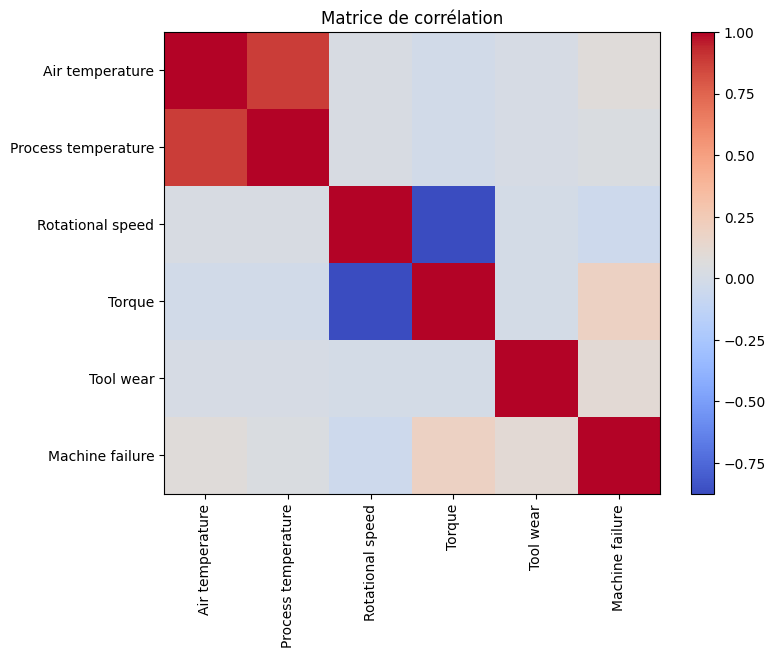

In [19]:
import matplotlib.pyplot as plt

corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Matrice de corrélation")
plt.show()

In [20]:
correlation_failure = corr["Machine failure"].sort_values(ascending=False)

print(correlation_failure)

Machine failure        1.000000
Torque                 0.191321
Tool wear              0.105448
Air temperature        0.082556
Process temperature    0.035946
Rotational speed      -0.044188
Name: Machine failure, dtype: float64


## 3. Préparation des données

### 3.1 Séparation entraînement / test

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    target,
    test_size=0.20,
    random_state=42,
    stratify=target
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)

print("\nRépartition train :")
print(y_train.value_counts())

print("\nRépartition test :")
print(y_test.value_counts())

X_train : (8000, 6)
X_test  : (2000, 6)

Répartition train :
Machine failure
0    7729
1     271
Name: count, dtype: int64

Répartition test :
Machine failure
0    1932
1      68
Name: count, dtype: int64


### 3.2 Encodage et standardisation

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = ["Type"]

numeric_features = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

## 4. Modélisation initiale

### 4.1 Régression logistique

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

In [24]:
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature',
                                                   'Process temperature',
                                                   'Rotational speed', 'Torque',
                                                   'Tool wear']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('model', LogisticRegression(max_iter=1000))])

In [25]:
y_pred = logistic_model.predict(X_test)

In [26]:
import pandas as pd

print(pd.Series(y_pred).value_counts())

0    1989
1      11
Name: count, dtype: int64


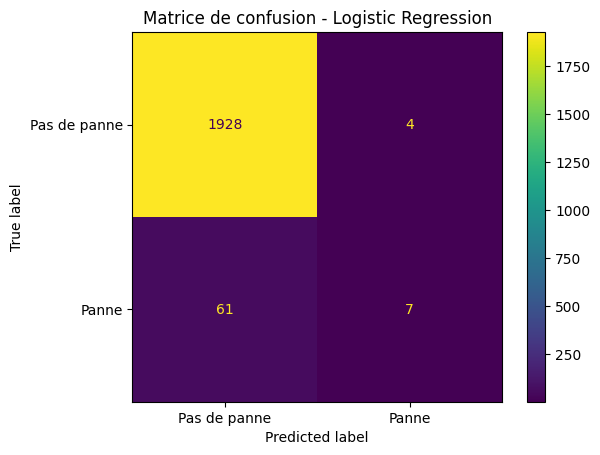

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Pas de panne", "Panne"]
)

disp.plot()
plt.title("Matrice de confusion - Logistic Regression")
plt.show()

In [28]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Pas de panne", "Panne"]
    )
)

              precision    recall  f1-score   support

Pas de panne       0.97      1.00      0.98      1932
       Panne       0.64      0.10      0.18        68

    accuracy                           0.97      2000
   macro avg       0.80      0.55      0.58      2000
weighted avg       0.96      0.97      0.96      2000



### 4.2 Gestion du déséquilibre — Régression logistique équilibrée

In [29]:
balanced_logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

In [30]:
balanced_logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature',
                                                   'Process temperature',
                                                   'Rotational speed', 'Torque',
                                                   'Tool wear']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [31]:
y_pred_balanced = balanced_logistic_model.predict(X_test)

In [32]:
print(
    classification_report(
        y_test,
        y_pred_balanced,
        target_names=["Pas de panne", "Panne"]
    )
)

              precision    recall  f1-score   support

Pas de panne       0.99      0.82      0.90      1932
       Panne       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



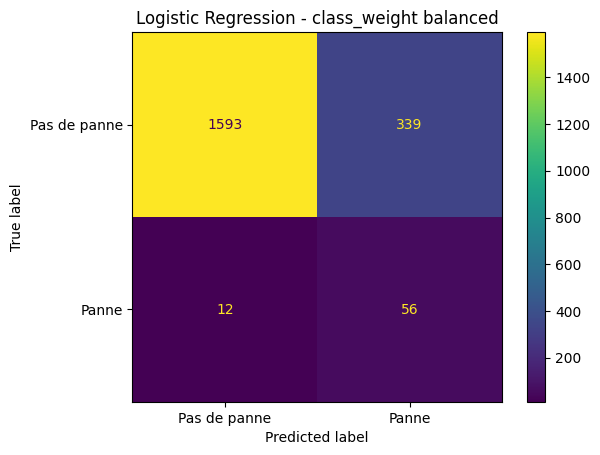

In [33]:
cm_balanced = confusion_matrix(y_test, y_pred_balanced)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=["Pas de panne", "Panne"]
)

disp.plot()
plt.title("Logistic Regression - class_weight balanced")
plt.show()

In [34]:
y_proba_balanced = balanced_logistic_model.predict_proba(X_test)[:, 1]

print(y_proba_balanced[:10])

[0.97135024 0.5379081  0.68019628 0.0104768  0.85478776 0.64133042
 0.78099336 0.1301747  0.03975587 0.52514664]


In [35]:
from sklearn.metrics import roc_auc_score, average_precision_score

roc_auc = roc_auc_score(y_test, y_proba_balanced)
pr_auc = average_precision_score(y_test, y_proba_balanced)

print("ROC-AUC :", roc_auc)
print("PR-AUC  :", pr_auc)

ROC-AUC : 0.9069540859822189
PR-AUC  : 0.38176196610560775


In [36]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

for threshold in thresholds:
    y_pred_threshold = (y_proba_balanced >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(
        f"Seuil {threshold:.1f} | "
        f"Precision = {precision:.2f} | "
        f"Recall = {recall:.2f} | "
        f"F1 = {f1:.2f}"
    )

Seuil 0.3 | Precision = 0.09 | Recall = 0.93 | F1 = 0.17
Seuil 0.4 | Precision = 0.12 | Recall = 0.90 | F1 = 0.20
Seuil 0.5 | Precision = 0.14 | Recall = 0.82 | F1 = 0.24
Seuil 0.6 | Precision = 0.18 | Recall = 0.76 | F1 = 0.30
Seuil 0.7 | Precision = 0.25 | Recall = 0.74 | F1 = 0.37
Seuil 0.8 | Precision = 0.34 | Recall = 0.59 | F1 = 0.43


**DecisionTree**

In [37]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

In [38]:
decision_tree_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature',
                                                   'Process temperature',
                                                   'Rotational speed', 'Torque',
                                                   'Tool wear']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('model',
                 DecisionTreeClassifier(class_weight='balanced',
                                        random_state=42))])

In [39]:
y_pred_tree = decision_tree_model.predict(X_test)

In [40]:
print(
    classification_report(
        y_test,
        y_pred_tree,
        target_names=["Pas de panne", "Panne"]
    )
)

              precision    recall  f1-score   support

Pas de panne       0.99      0.99      0.99      1932
       Panne       0.69      0.60      0.65        68

    accuracy                           0.98      2000
   macro avg       0.84      0.80      0.82      2000
weighted avg       0.98      0.98      0.98      2000



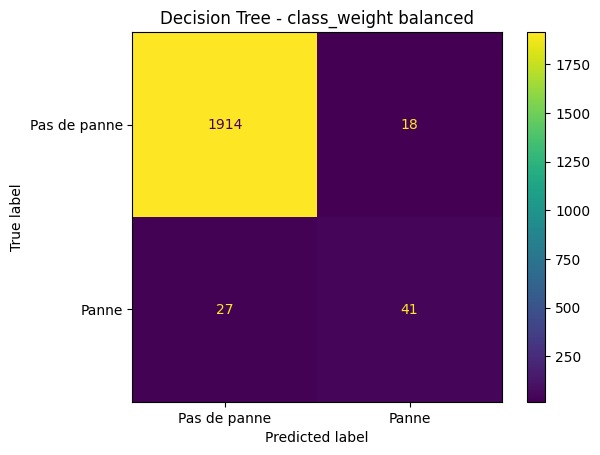

In [41]:
cm_tree = confusion_matrix(y_test, y_pred_tree)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=["Pas de panne", "Panne"]
)

disp.plot()
plt.title("Decision Tree - class_weight balanced")
plt.show()

In [42]:
y_proba_tree = decision_tree_model.predict_proba(X_test)[:, 1]

roc_auc_tree = roc_auc_score(y_test, y_proba_tree)
pr_auc_tree = average_precision_score(y_test, y_proba_tree)

print("ROC-AUC :", roc_auc_tree)
print("PR-AUC  :", pr_auc_tree)

ROC-AUC : 0.7968122031421265
PR-AUC  : 0.43249302093718844



**KNN**

In [43]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", KNeighborsClassifier(
        n_neighbors=5
    ))
])

In [45]:
knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

In [46]:
print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=["Pas de panne", "Panne"]
    )
)

              precision    recall  f1-score   support

Pas de panne       0.98      1.00      0.99      1932
       Panne       0.83      0.29      0.43        68

    accuracy                           0.97      2000
   macro avg       0.90      0.65      0.71      2000
weighted avg       0.97      0.97      0.97      2000



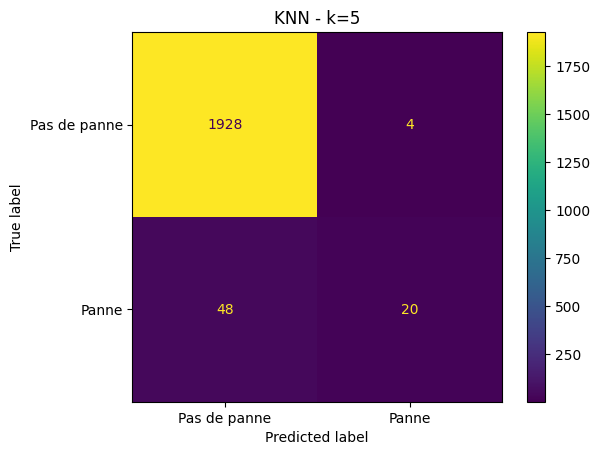

In [47]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["Pas de panne", "Panne"]
)

disp.plot()
plt.title("KNN - k=5")
plt.show()

In [48]:
y_proba_knn = knn_model.predict_proba(X_test)[:, 1]

roc_auc_knn = roc_auc_score(y_test, y_proba_knn)
pr_auc_knn = average_precision_score(y_test, y_proba_knn)

print("ROC-AUC :", roc_auc_knn)
print("PR-AUC  :", pr_auc_knn)

ROC-AUC : 0.8290859822189744
PR-AUC  : 0.45855194805194804


**Random Forest**

In [50]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ))
])

In [51]:
random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)

In [52]:
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Pas de panne", "Panne"]
    )
)

              precision    recall  f1-score   support

Pas de panne       0.98      1.00      0.99      1932
       Panne       0.97      0.43      0.59        68

    accuracy                           0.98      2000
   macro avg       0.97      0.71      0.79      2000
weighted avg       0.98      0.98      0.98      2000



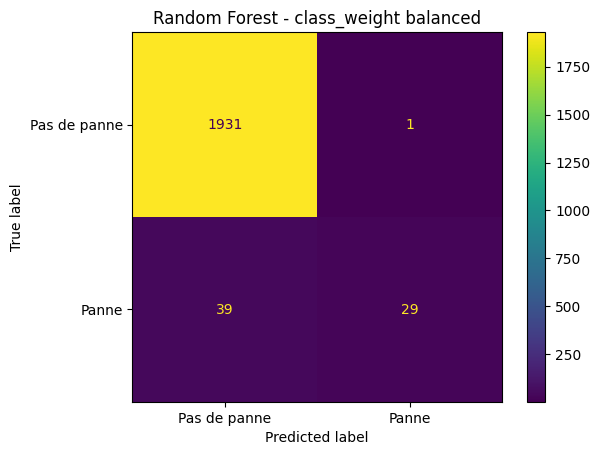

In [53]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Pas de panne", "Panne"]
)

disp.plot()
plt.title("Random Forest - class_weight balanced")
plt.show()

In [54]:
y_proba_rf = random_forest_model.predict_proba(X_test)[:, 1]

roc_auc_rf = roc_auc_score(y_test, y_proba_rf)
pr_auc_rf = average_precision_score(y_test, y_proba_rf)

print("ROC-AUC :", roc_auc_rf)
print("PR-AUC  :", pr_auc_rf)

ROC-AUC : 0.9635017050298381
PR-AUC  : 0.7642407582429013


### 4.6 XGBoost

In [55]:
from xgboost import XGBClassifier

xgb_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        scale_pos_weight=28.52,
        random_state=42,
        eval_metric="logloss"
    ))
])

In [57]:
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

In [58]:
print(
    classification_report(
        y_test,
        y_pred_xgb,
        target_names=["Pas de panne", "Panne"]
    )
)

              precision    recall  f1-score   support

Pas de panne       1.00      0.92      0.96      1932
       Panne       0.29      0.88      0.43        68

    accuracy                           0.92      2000
   macro avg       0.64      0.90      0.70      2000
weighted avg       0.97      0.92      0.94      2000



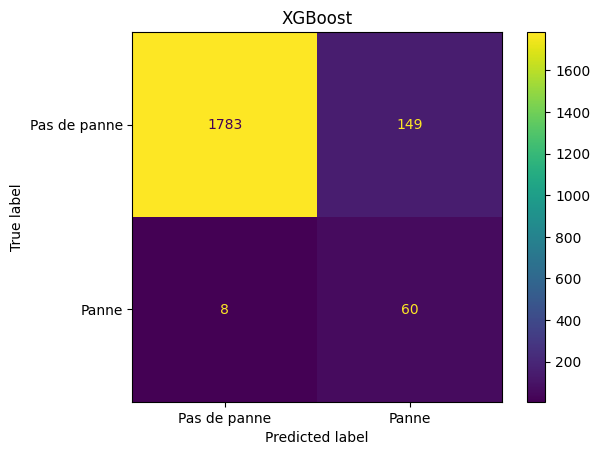

In [59]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Pas de panne", "Panne"]
)

disp.plot()
plt.title("XGBoost")
plt.show()

In [60]:
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

roc_auc_xgb = roc_auc_score(y_test, y_proba_xgb)
pr_auc_xgb = average_precision_score(y_test, y_proba_xgb)

print("ROC-AUC :", roc_auc_xgb)
print("PR-AUC  :", pr_auc_xgb)

ROC-AUC : 0.9659755206430398
PR-AUC  : 0.7114089957289369


In [61]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Random Forest",
        "XGBoost"
    ],
    "Precision_failure": [0.14, 0.69, 0.83, 0.97, 0.29],
    "Recall_failure": [0.82, 0.60, 0.29, 0.43, 0.88],
    "F1_failure": [0.24, 0.65, 0.43, 0.59, 0.43],
    "ROC_AUC": [
        0.907,
        0.797,
        0.829,
        0.964,
        0.966
    ],
    "PR_AUC": [
        0.382,
        0.432,
        0.459,
        0.764,
        0.711
    ]
})

display(results)

,Model,Precision_failure,Recall_failure,F1_failure,ROC_AUC,PR_AUC
0,Logistic Regression,0.14,0.82,0.24,0.907,0.382
1,Decision Tree,0.69,0.60,0.65,0.797,0.432
2,KNN,0.83,0.29,0.43,0.829,0.459
3,Random Forest,0.97,0.43,0.59,0.964,0.764
4,XGBoost,0.29,0.88,0.43,0.966,0.711


## 5. Optimisation des hyperparamètres

**optimisation Decion treee**

In [62]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid_tree = {
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_tree = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=param_grid_tree,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

In [63]:
grid_tree.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['Air '
                                                                          'temperature',
                                                                          'Process '
                                                                          'temperature',
                                                                          'Rotational '
                                                                          'speed',
                                                                          'Torque',
                                                                          'Tool '
                                                                          'wear']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['Type'])])),
                                       ('model',
                                        DecisionTreeClassifier(class_weight='balanced',
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [3, 5, 7, 10, None],
                         'model__min_samples_leaf': [1, 2, 5],
                         'model__min_samples_split': [2, 5, 10]},
             scoring='f1')

In [64]:
print("Meilleurs paramètres :")
print(grid_tree.best_params_)

print("\nMeilleur F1 moyen en cross-validation :")
print(grid_tree.best_score_)

Meilleurs paramètres :
{'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2}

Meilleur F1 moyen en cross-validation :
0.6420139696794018


In [65]:
best_tree = grid_tree.best_estimator_

y_pred_best_tree = best_tree.predict(X_test)

print(
    classification_report(
        y_test,
        y_pred_best_tree,
        target_names=["Pas de panne", "Panne"]
    )
)

              precision    recall  f1-score   support

Pas de panne       0.99      0.99      0.99      1932
       Panne       0.70      0.69      0.70        68

    accuracy                           0.98      2000
   macro avg       0.85      0.84      0.84      2000
weighted avg       0.98      0.98      0.98      2000



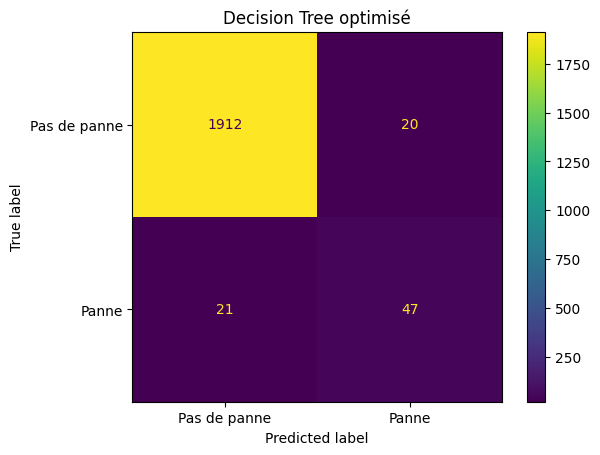

In [66]:
cm_best_tree = confusion_matrix(y_test, y_pred_best_tree)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_tree,
    display_labels=["Pas de panne", "Panne"]
)

disp.plot()
plt.title("Decision Tree optimisé")
plt.show()

In [67]:
y_proba_best_tree = best_tree.predict_proba(X_test)[:, 1]

print("ROC-AUC :", roc_auc_score(y_test, y_proba_best_tree))
print("PR-AUC  :", average_precision_score(y_test, y_proba_best_tree))

ROC-AUC : 0.8419231823164048
PR-AUC  : 0.5677411403567085


**optimisation du Random Forest**

In [68]:
param_grid_rf = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", "log2"]
}

In [69]:
from sklearn.model_selection import GridSearchCV

grid_rf = GridSearchCV(
    estimator=random_forest_model,
    param_grid=param_grid_rf,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['Air '
                                                                          'temperature',
                                                                          'Process '
                                                                          'temperature',
                                                                          'Rotational '
                                                                          'speed',
                                                                          'Torque',
                                                                          'Tool '
                                                                          'wear']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['Type'])])),
                                       ('model',
                                        RandomForestClassifier(class_weight='balanced',
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [None, 5, 10],
                         'model__max_features': ['sqrt', 'log2'],
                         'model__min_samples_leaf': [1, 2],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [100, 200]},
             scoring='f1')

In [74]:
print("Meilleurs paramètres :")
print(grid_rf.best_params_)

print("\nMeilleur F1 moyen en cross-validation :")
print(grid_rf.best_score_)

Meilleurs paramètres :
{'model__max_depth': None, 'model__max_features': 'log2', 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 100}

Meilleur F1 moyen en cross-validation :
0.6802904844104003


In [75]:
best_rf = grid_rf.best_estimator_
y_pred_best_rf = best_rf.predict(X_test)
print(
    classification_report(
        y_test,
        y_pred_best_rf,
        target_names=["Pas de panne", "Panne"]
    )
)

              precision    recall  f1-score   support

Pas de panne       0.99      0.99      0.99      1932
       Panne       0.81      0.65      0.72        68

    accuracy                           0.98      2000
   macro avg       0.90      0.82      0.86      2000
weighted avg       0.98      0.98      0.98      2000



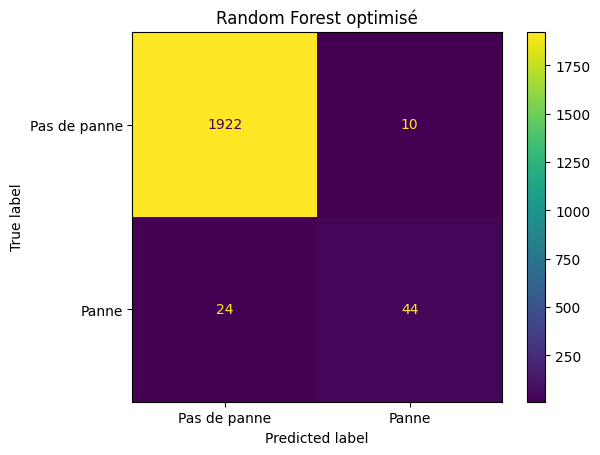

In [76]:
cm_best_rf = confusion_matrix(y_test, y_pred_best_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_rf,
    display_labels=["Pas de panne", "Panne"]
)

disp.plot()
plt.title("Random Forest optimisé")
plt.show()

In [77]:
y_proba_best_rf = best_rf.predict_proba(X_test)[:, 1]

print("ROC-AUC :", roc_auc_score(y_test, y_proba_best_rf))
print("PR-AUC  :", average_precision_score(y_test, y_proba_best_rf))

ROC-AUC : 0.9686510473754721
PR-AUC  : 0.8035220029248985


**optimations xgboost**

In [78]:
from sklearn.model_selection import GridSearchCV

param_grid_xgb = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [2, 3, 4],
    "model__learning_rate": [0.05, 0.1],
    "model__subsample": [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid_xgb,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

grid_xgb.fit(X_train, y_train)

print("Meilleurs paramètres :")
print(grid_xgb.best_params_)

print("\nMeilleur F1 moyen en cross-validation :")
print(grid_xgb.best_score_)

Meilleurs paramètres :
{'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 200, 'model__subsample': 0.8}

Meilleur F1 moyen en cross-validation :
0.6916149788968686


Classification report :
              precision    recall  f1-score   support

Pas de panne       0.99      0.98      0.99      1932
       Panne       0.59      0.82      0.69        68

    accuracy                           0.97      2000
   macro avg       0.79      0.90      0.84      2000
weighted avg       0.98      0.97      0.98      2000



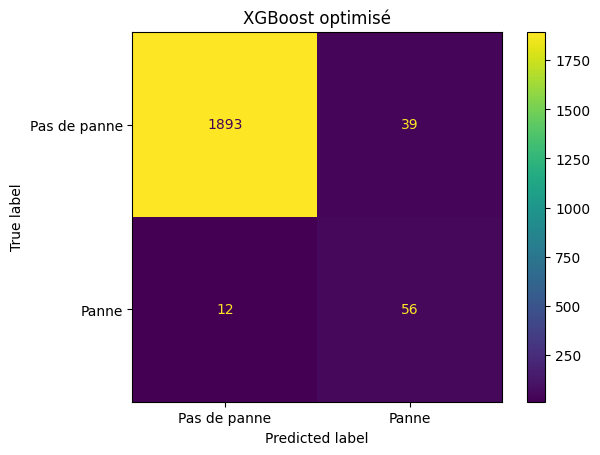

ROC-AUC : 0.9731381683108026
PR-AUC  : 0.8171428808149063


In [79]:
# Récupérer le meilleur XGBoost trouvé par GridSearch
best_xgb = grid_xgb.best_estimator_

# Prédictions sur le jeu de test
y_pred_best_xgb = best_xgb.predict(X_test)

# Rapport de classification
print("Classification report :")
print(
    classification_report(
        y_test,
        y_pred_best_xgb,
        target_names=["Pas de panne", "Panne"]
    )
)

# Matrice de confusion
cm_best_xgb = confusion_matrix(y_test, y_pred_best_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_xgb,
    display_labels=["Pas de panne", "Panne"]
)

disp.plot()
plt.title("XGBoost optimisé")
plt.show()

# Probabilités de la classe panne
y_proba_best_xgb = best_xgb.predict_proba(X_test)[:, 1]

# ROC-AUC et PR-AUC
roc_auc_best_xgb = roc_auc_score(y_test, y_proba_best_xgb)
pr_auc_best_xgb = average_precision_score(y_test, y_proba_best_xgb)

print("ROC-AUC :", roc_auc_best_xgb)
print("PR-AUC  :", pr_auc_best_xgb)

### 5.4 Optimisation de KNN

In [80]:
param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

grid_knn = GridSearchCV(
    estimator=knn_model,
    param_grid=param_grid_knn,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print("Meilleurs paramètres :")
print(grid_knn.best_params_)

print("\nMeilleur F1 moyen en cross-validation :")
print(grid_knn.best_score_)

Meilleurs paramètres :
{'model__n_neighbors': 3, 'model__p': 2, 'model__weights': 'distance'}

Meilleur F1 moyen en cross-validation :
0.4927365284729627


              precision    recall  f1-score   support

Pas de panne       0.98      0.99      0.99      1932
       Panne       0.62      0.38      0.47        68

    accuracy                           0.97      2000
   macro avg       0.80      0.69      0.73      2000
weighted avg       0.97      0.97      0.97      2000



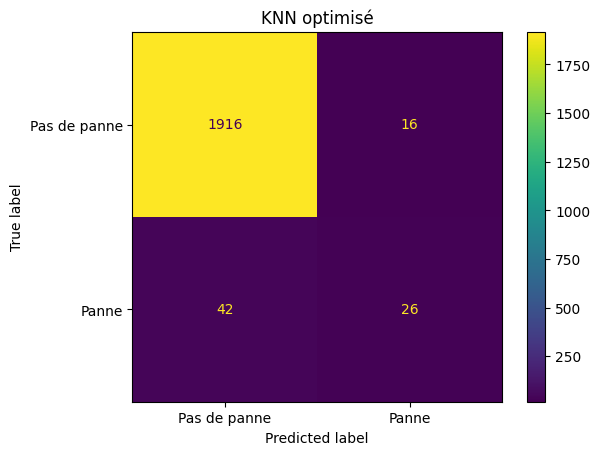

ROC-AUC : 0.787807514310072
PR-AUC  : 0.4006804293877634


In [81]:
best_knn = grid_knn.best_estimator_

# Prédiction sur X_test
y_pred_best_knn = best_knn.predict(X_test)

# Classification report
print(
    classification_report(
        y_test,
        y_pred_best_knn,
        target_names=["Pas de panne", "Panne"]
    )
)

# Matrice de confusion
cm_best_knn = confusion_matrix(y_test, y_pred_best_knn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_knn,
    display_labels=["Pas de panne", "Panne"]
)

disp.plot()
plt.title("KNN optimisé")
plt.show()

# Probabilités
y_proba_best_knn = best_knn.predict_proba(X_test)[:, 1]

# AUC
print("ROC-AUC :", roc_auc_score(y_test, y_proba_best_knn))
print("PR-AUC  :", average_precision_score(y_test, y_proba_best_knn))

### 5.5 Optimisation de la régression logistique

In [82]:
param_grid_logistic = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

grid_logistic = GridSearchCV(
    estimator=balanced_logistic_model,
    param_grid=param_grid_logistic,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

grid_logistic.fit(X_train, y_train)

print("Meilleurs paramètres :")
print(grid_logistic.best_params_)

print("\nMeilleur F1 moyen en cross-validation :")
print(grid_logistic.best_score_)


Meilleurs paramètres :
{'model__C': 1, 'model__solver': 'lbfgs'}

Meilleur F1 moyen en cross-validation :
0.23457038927750937


              precision    recall  f1-score   support

Pas de panne       0.99      0.82      0.90      1932
       Panne       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



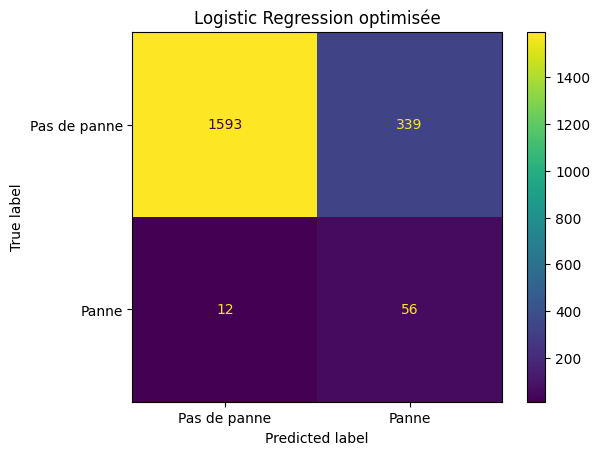

ROC-AUC : 0.9069540859822189
PR-AUC : 0.38176196610560775


In [83]:
# Meilleure Logistic Regression
best_logistic = grid_logistic.best_estimator_

# Prédictions
y_pred_best_logistic = best_logistic.predict(X_test)

# Classification report
print(
    classification_report(
        y_test,
        y_pred_best_logistic,
        target_names=["Pas de panne", "Panne"]
    )
)

# Matrice de confusion
cm_best_logistic = confusion_matrix(
    y_test,
    y_pred_best_logistic
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_logistic,
    display_labels=["Pas de panne", "Panne"]
)

disp.plot()
plt.title("Logistic Regression optimisée")
plt.show()

# Probabilités
y_proba_best_logistic = best_logistic.predict_proba(X_test)[:, 1]

# ROC-AUC et PR-AUC
print(
    "ROC-AUC :",
    roc_auc_score(y_test, y_proba_best_logistic)
)

print(
    "PR-AUC :",
    average_precision_score(
        y_test,
        y_proba_best_logistic
    )
)

## 6. Comparaison des modèles optimisés

### 6.1 Tableau comparatif des performances

In [84]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results_optimized = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Random Forest",
        "XGBoost"
    ],

    "Precision": [
        precision_score(y_test, y_pred_best_logistic),
        precision_score(y_test, y_pred_best_tree),
        precision_score(y_test, y_pred_best_knn),
        precision_score(y_test, y_pred_best_rf),
        precision_score(y_test, y_pred_best_xgb)
    ],

    "Recall": [
        recall_score(y_test, y_pred_best_logistic),
        recall_score(y_test, y_pred_best_tree),
        recall_score(y_test, y_pred_best_knn),
        recall_score(y_test, y_pred_best_rf),
        recall_score(y_test, y_pred_best_xgb)
    ],

    "F1-score": [
        f1_score(y_test, y_pred_best_logistic),
        f1_score(y_test, y_pred_best_tree),
        f1_score(y_test, y_pred_best_knn),
        f1_score(y_test, y_pred_best_rf),
        f1_score(y_test, y_pred_best_xgb)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_proba_best_logistic),
        roc_auc_score(y_test, y_proba_best_tree),
        roc_auc_score(y_test, y_proba_best_knn),
        roc_auc_score(y_test, y_proba_best_rf),
        roc_auc_score(y_test, y_proba_best_xgb)
    ],

    "PR-AUC": [
        average_precision_score(y_test, y_proba_best_logistic),
        average_precision_score(y_test, y_proba_best_tree),
        average_precision_score(y_test, y_proba_best_knn),
        average_precision_score(y_test, y_proba_best_rf),
        average_precision_score(y_test, y_proba_best_xgb)
    ]
})

display(results_optimized.round(3))

,Model,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.142,0.824,0.242,0.907,0.382
1,Decision Tree,0.701,0.691,0.696,0.842,0.568
2,KNN,0.619,0.382,0.473,0.788,0.401
3,Random Forest,0.815,0.647,0.721,0.969,0.804
4,XGBoost,0.589,0.824,0.687,0.973,0.817


### 6.2 Courbes ROC

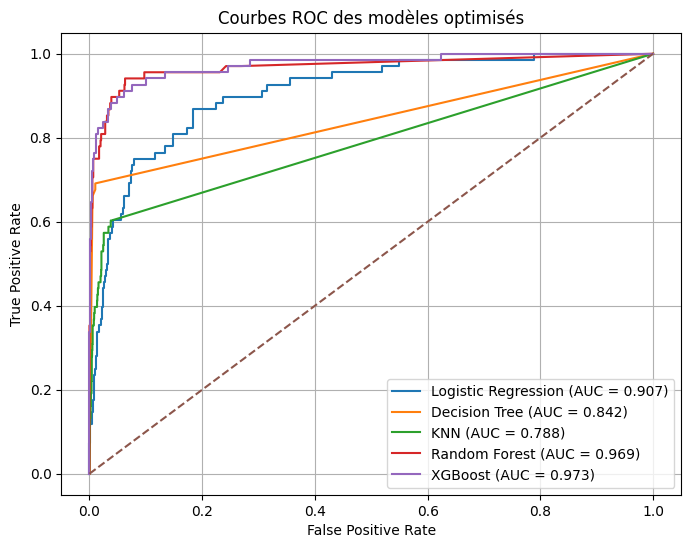

In [85]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

models_proba = {
    "Logistic Regression": y_proba_best_logistic,
    "Decision Tree": y_proba_best_tree,
    "KNN": y_proba_best_knn,
    "Random Forest": y_proba_best_rf,
    "XGBoost": y_proba_best_xgb
}

plt.figure(figsize=(8, 6))

for name, proba in models_proba.items():
    fpr, tpr, thresholds = roc_curve(y_test, proba)

    auc = roc_auc_score(y_test, proba)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

# Ligne d'un modèle aléatoire
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Courbes ROC des modèles optimisés")
plt.legend()
plt.grid()
plt.show()

### 6.3 Courbes Precision-Recall

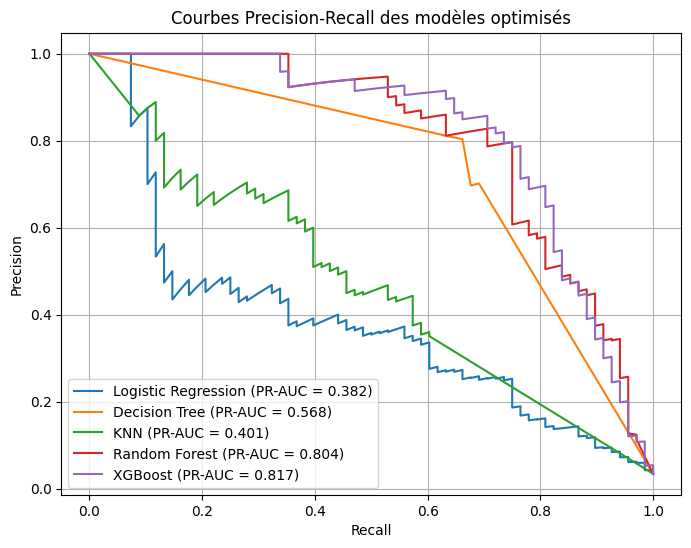

In [86]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, proba in models_proba.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        proba
    )

    pr_auc = average_precision_score(
        y_test,
        proba
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (PR-AUC = {pr_auc:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Courbes Precision-Recall des modèles optimisés")
plt.legend()
plt.grid()
plt.show()

## 7. Optimisation du seuil de décision

### 7.1 Étude Precision / Recall / F1 selon le seuil

In [87]:
import numpy as np
import pandas as pd

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

# Probabilités obtenues uniquement à partir de X_train
y_proba_cv = cross_val_predict(
    best_xgb,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Seuils à tester
thresholds = np.arange(0.30, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_proba_cv >= threshold
    ).astype(int)

    precision = precision_score(
        y_train,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_train,
        y_pred_threshold
    )

    f1 = f1_score(
        y_train,
        y_pred_threshold
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

,Threshold,Precision,Recall,F1
0,0.30,0.478,0.841,0.610
1,0.35,0.514,0.838,0.637
2,0.40,0.554,0.827,0.664
3,0.45,0.579,0.808,0.675
4,0.50,0.610,0.797,0.691
5,0.55,0.628,0.786,0.698
6,0.60,0.649,0.764,0.702
7,0.65,0.677,0.756,0.714
8,0.70,0.694,0.738,0.716
9,0.75,0.747,0.731,0.739


### 7.2 Évaluation finale avec le seuil retenu

              precision    recall  f1-score   support

Pas de panne       0.99      0.99      0.99      1932
       Panne       0.78      0.76      0.77        68

    accuracy                           0.98      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.98      0.98      0.98      2000



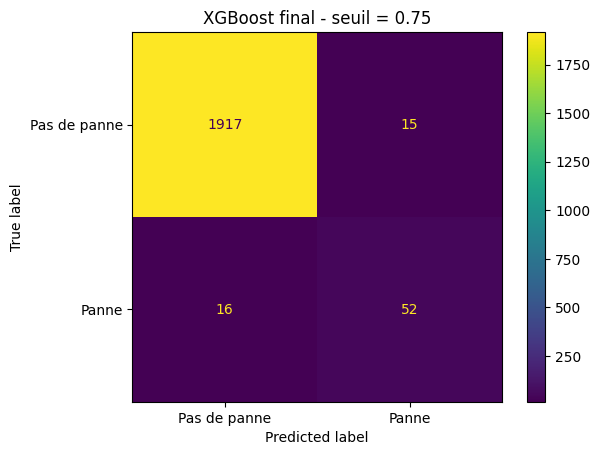

In [88]:
final_threshold = 0.75

# Probabilités XGBoost sur le test
y_proba_final = best_xgb.predict_proba(X_test)[:, 1]

# Application du seuil choisi
y_pred_final = (y_proba_final >= final_threshold).astype(int)

# Rapport final
print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=["Pas de panne", "Panne"]
    )
)

# Matrice de confusion
cm_final = confusion_matrix(y_test, y_pred_final)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["Pas de panne", "Panne"]
)

disp.plot()
plt.title("XGBoost final - seuil = 0.75")
plt.show()

## 8. Sauvegarde du modèle final

In [89]:
import joblib

final_model = {
    "model": best_xgb,
    "threshold": 0.75
}

joblib.dump(
    final_model,
    "/kaggle/working/predictive_maintenance_model.pkl"
)

print("Modèle sauvegardé.")

Modèle sauvegardé.


## 9. Prototype de l’API FastAPI

In [90]:
!pip install -q fastapi uvicorn httpx

In [91]:
%%writefile /kaggle/working/main.py

from fastapi import FastAPI
from pydantic import BaseModel
import pandas as pd
import joblib
from pathlib import Path

# Création de l'API
app = FastAPI(
    title="Predictive Maintenance API",
    description="API de prédiction des pannes de machines",
    version="1.0"
)

# Charger le modèle sauvegardé
MODEL_PATH = Path(__file__).parent / "predictive_maintenance_model.pkl"

saved_data = joblib.load(MODEL_PATH)

model = saved_data["model"]
threshold = saved_data["threshold"]


# Structure des données reçues
class MachineData(BaseModel):
    Type: str
    air_temperature: float
    process_temperature: float
    rotational_speed: int
    torque: float
    tool_wear: int


@app.get("/")
def home():
    return {
        "message": "Predictive Maintenance API is running"
    }


@app.post("/predict")
def predict(data: MachineData):

    # Transformer les données reçues en DataFrame
    machine = pd.DataFrame([{
        "Type": data.Type,
        "Air temperature": data.air_temperature,
        "Process temperature": data.process_temperature,
        "Rotational speed": data.rotational_speed,
        "Torque": data.torque,
        "Tool wear": data.tool_wear
    }])

    # Score prédit pour la classe panne
    failure_score = model.predict_proba(machine)[0, 1]

    # Appliquer notre seuil choisi
    prediction = int(failure_score >= threshold)

    return {
        "prediction": prediction,
        "label": "Panne" if prediction == 1 else "Pas de panne",
        "failure_score": float(failure_score),
        "threshold": threshold
    }

Writing /kaggle/working/main.py


In [95]:
from fastapi.testclient import TestClient
import sys

sys.path.append("/kaggle/working")

from main import app

client = TestClient(app)

response = client.post(
    "/predict",
    json={
        "Type": "L",
        "air_temperature": 301.5,
        "process_temperature": 311.0,
        "rotational_speed": 1350,
        "torque": 55.0,
        "tool_wear": 180
    }
)

print("Status :", response.status_code)
print(response.json())

Status : 200
{'prediction': 0, 'label': 'Pas de panne', 'failure_score': 0.021767379716038704, 'threshold': 0.75}


In [96]:
# Trouver une vraie panne dans le jeu de test
failure_index = y_test[y_test == 1].index[0]

machine_failure = X_test.loc[failure_index]

print(machine_failure)
print("Vraie classe :", y_test.loc[failure_index])

Type                       L
Air temperature        303.7
Process temperature    312.1
Rotational speed        1363
Torque                  51.8
Tool wear                 90
Name: 4851, dtype: object
Vraie classe : 1


In [97]:
response = client.post(
    "/predict",
    json={
        "Type": str(machine_failure["Type"]),
        "air_temperature": float(machine_failure["Air temperature"]),
        "process_temperature": float(machine_failure["Process temperature"]),
        "rotational_speed": int(machine_failure["Rotational speed"]),
        "torque": float(machine_failure["Torque"]),
        "tool_wear": int(machine_failure["Tool wear"])
    }
)

print("Status :", response.status_code)
print("Réponse API :", response.json())

Status : 200
Réponse API : {'prediction': 0, 'label': 'Pas de panne', 'failure_score': 0.40353500843048096, 'threshold': 0.75}


In [98]:
# Scores de toutes les machines du test
test_scores = best_xgb.predict_proba(X_test)[:, 1]

# Copier X_test pour faciliter la recherche
test_check = X_test.copy()

test_check["true_label"] = y_test
test_check["failure_score"] = test_scores

# Garder uniquement les vraies pannes correctement détectables au seuil 0.75
true_positive_examples = test_check[
    (test_check["true_label"] == 1) &
    (test_check["failure_score"] >= 0.75)
]

display(true_positive_examples.head())

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,true_label,failure_score
1391,L,298.9,310.2,2737,8.8,142,1,0.987661
4495,L,302.6,310.4,1359,57.2,67,1,0.996123
8582,M,297.5,308.1,1334,72.0,151,1,0.984045
9664,L,299.1,310.2,1317,54.8,231,1,0.992717
4632,M,302.9,311.2,1330,53.7,200,1,0.790025


In [99]:
machine_failure = true_positive_examples.iloc[0]

response = client.post(
    "/predict",
    json={
        "Type": str(machine_failure["Type"]),
        "air_temperature": float(machine_failure["Air temperature"]),
        "process_temperature": float(machine_failure["Process temperature"]),
        "rotational_speed": int(machine_failure["Rotational speed"]),
        "torque": float(machine_failure["Torque"]),
        "tool_wear": int(machine_failure["Tool wear"])
    }
)

print("Réponse API :", response.json())

Réponse API : {'prediction': 1, 'label': 'Panne', 'failure_score': 0.9876606464385986, 'threshold': 0.75}
